# Constructing fractional differences from binomial weights

A fractional difference combines the present level with a weighted history whose weights follow the binomial rule:

$$
(1-B)^d X_t=sum_{k=0}^{infty}omega_k X_{t-k},qquad
omega_0=1,qquad
omega_k=-\omega_{k-1}\frac{d-k+1}{k}.
$$

Here, $X_t$ is the value at time $t$; $B$ shifts a value back one time step, so $B^kX_t=X_{t-k}.$ $d\geq0$ is the difference order; $k$ is the lag; $\omega_k$ is the weight on the value $k$ steps back.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("08_fractional_differentiation");
using CSV, Printf, HypothesisTests
using RiskLabAI.Data: calculate_weights_std,calculate_weights_ffd,fractional_difference_std,fractional_difference_fixed,adaptive_fractional_difference
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
minute_close = raw.close
resampled = combine(groupby(DataFrame(time=floor.(raw.time,Minute(15)),price=raw.close),:time;sort=true),:price=>last=>:close)
close_index,close_prices = resampled.time,resampled.close
log_price = log.(close_prices)
violet = "#C084FC"

function natural_weights(degree,size)
    values = ones(size)
    for lag in 1:size-1
        values[lag+1] = -values[lag]*(degree-lag+1)/lag
    end
    return values
end

function adf_record(values)
    test = ADFTest(Float64.(values),:constant,1)
    return (statistic=test.stat,p_value=pvalue(test),lag=test.lag,observations=test.n,critical=HypothesisTests.adf_cv(test.n,:constant)[2])
end

function fixed_transform(values,degree,cutoff)
    transformed = fractional_difference_fixed(values,degree;threshold=cutoff)
    positions = findall(isfinite,transformed)
    return (positions=positions,values=transformed[positions])
end

function save_adf_records(records,stem)
    save_data(DataFrame(records),paths,stem)
    return nothing
end


save_adf_records (generic function with 1 method)

## From Integer Steps to Fractional Steps

In [2]:
data_provenance = DataFrame("Field"=>["Archive","Provider","Public access","Market","Minute records","Analysis interval","Analysis records","First analysis time","Last analysis time"],"Value"=>["BTCUSDT-1m-2021-01.zip","Binance Data Vision","Direct public download","Bitcoin quoted in USDT",string(length(minute_close)),"Fifteen minutes",string(length(close_prices)),string(first(close_index)),string(last(close_index))])
degrees = [0.,.1,.2,.5,.8,1.]
boundary_rows,recurrence_rows,decay_rows,weight_rows = NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[]
for degree in [0.,.5,1.]
    for (position,value) in enumerate(natural_weights(degree,6))
        push!(boundary_rows,(order=degree,lag=position-1,weight=value))
    end
end
boundary_weights = DataFrame(boundary_rows)
rename!(boundary_weights,["Order","Lag","Weight"])
for degree in degrees
    direct = natural_weights(degree,80)
    released = reverse(calculate_weights_std(degree,80))
    push!(recurrence_rows,(order=degree,gap=maximum(abs.(direct.-released)),first=direct[1],second=direct[2],sum=sum(direct)))
end
recurrence_check = DataFrame(recurrence_rows)
rename!(recurrence_check,["Order","Largest absolute difference","First weight","Second weight","Partial sum through lag 79"])
for degree in [.1,.2,.5,.8]
    weights = natural_weights(degree,2000)
    push!(decay_rows,(order=degree,first=weights[2],tenth=weights[11],hundredth=weights[101],sum=sum(weights),mass=sum(abs.(weights))))
end
for degree in degrees
    weights = natural_weights(degree,2000)
    released = reverse(calculate_weights_std(degree,2000))
    for position in eachindex(weights)
        push!(weight_rows,(order=degree,lag=position-1,natural=weights[position],released=released[position]))
    end
end
weight_decay_summary = DataFrame(decay_rows)
rename!(weight_decay_summary,["Order","Weight at lag 1","Weight at lag 10","Weight at lag 100","Partial sum through lag 1999","Absolute weight mass"])
save_table(data_provenance,paths,"data_provenance";caption="Public data used in Chapter 7.",label="tab:chapter7-data-provenance")
save_table(boundary_weights,paths,"boundary_weights";caption="First six weights for the two endpoint orders and one fractional order.",label="tab:chapter7-boundary-weights")
save_table(recurrence_check,paths,"recurrence_check";caption="Independent and released binomial-weight calculations.",label="tab:chapter7-recurrence-check")
save_table(weight_decay_summary,paths,"weight_decay_summary";caption="Decay of fractional weights over long lags.",label="tab:chapter7-weight-decay")
save_data(DataFrame(weight_rows),paths,"fractional_weights")
save_data(DataFrame(time=close_index,close=close_prices,log_price=log_price),paths,"resampled_prices");


Row,Field,Value
,String,String
1,Archive,BTCUSDT-1m-2021-01.zip
2,Provider,Binance Data Vision
3,Public access,Direct public download
4,Market,Bitcoin quoted in USDT
5,Minute records,44640
6,Analysis interval,Fifteen minutes
7,Analysis records,2976
8,First analysis time,2021-01-01T00:00:00
9,Last analysis time,2021-01-31T23:45:00


Row,Order,Lag,Weight
,Float64,Int64,Float64
1,0.0,0,1.0
2,0.0,1,-0.0
3,0.0,2,-0.0
4,0.0,3,-0.0
5,0.0,4,-0.0
6,0.0,5,-0.0
7,0.5,0,1.0
8,0.5,1,-0.5
9,0.5,2,-0.125


Row,Order,Largest absolute difference,First weight,Second weight,Partial sum through lag 79
,Float64,Float64,Float64,Float64,Float64
1,0.0,0.0,1.0,-0.0,1.0
2,0.1,3.46945e-18,1.0,-0.1,0.604176
3,0.2,3.46945e-18,1.0,-0.2,0.358094
4,0.5,4.33681e-19,1.0,-0.5,0.0633759
5,0.8,4.33681e-19,1.0,-0.8,0.00660033
6,1.0,0.0,1.0,-1.0,0.0


Row,Order,Weight at lag 1,Weight at lag 10,Weight at lag 100,Partial sum through lag 1999,Absolute weight mass
,Float64,Float64,Float64,Float64,Float64,Float64
1,0.1,-0.1,-0.00747498,-0.000590762,0.437605,1.5624
2,0.2,-0.2,-0.010973,-0.000684721,0.187837,1.81216
3,0.5,-0.5,-0.00927353,-0.000283158,0.012618,1.98738
4,0.8,-0.8,-0.00297784,-4.40898e-5,0.000498241,1.9995


## Boundary Cases

Order zero leaves the series unchanged, while order one gives the ordinary first difference:

$$
(1-B)^0X_t=X_t,qquad
(1-B)^1X_t=X_t-X_{t-1}.
$$

Here, $X_t$ is the current level; $X_{t-1}$ is the preceding level; $B$ is the one-step backshift. $d=0$ is the unchanged endpoint and $d=1$ is the first-difference endpoint.

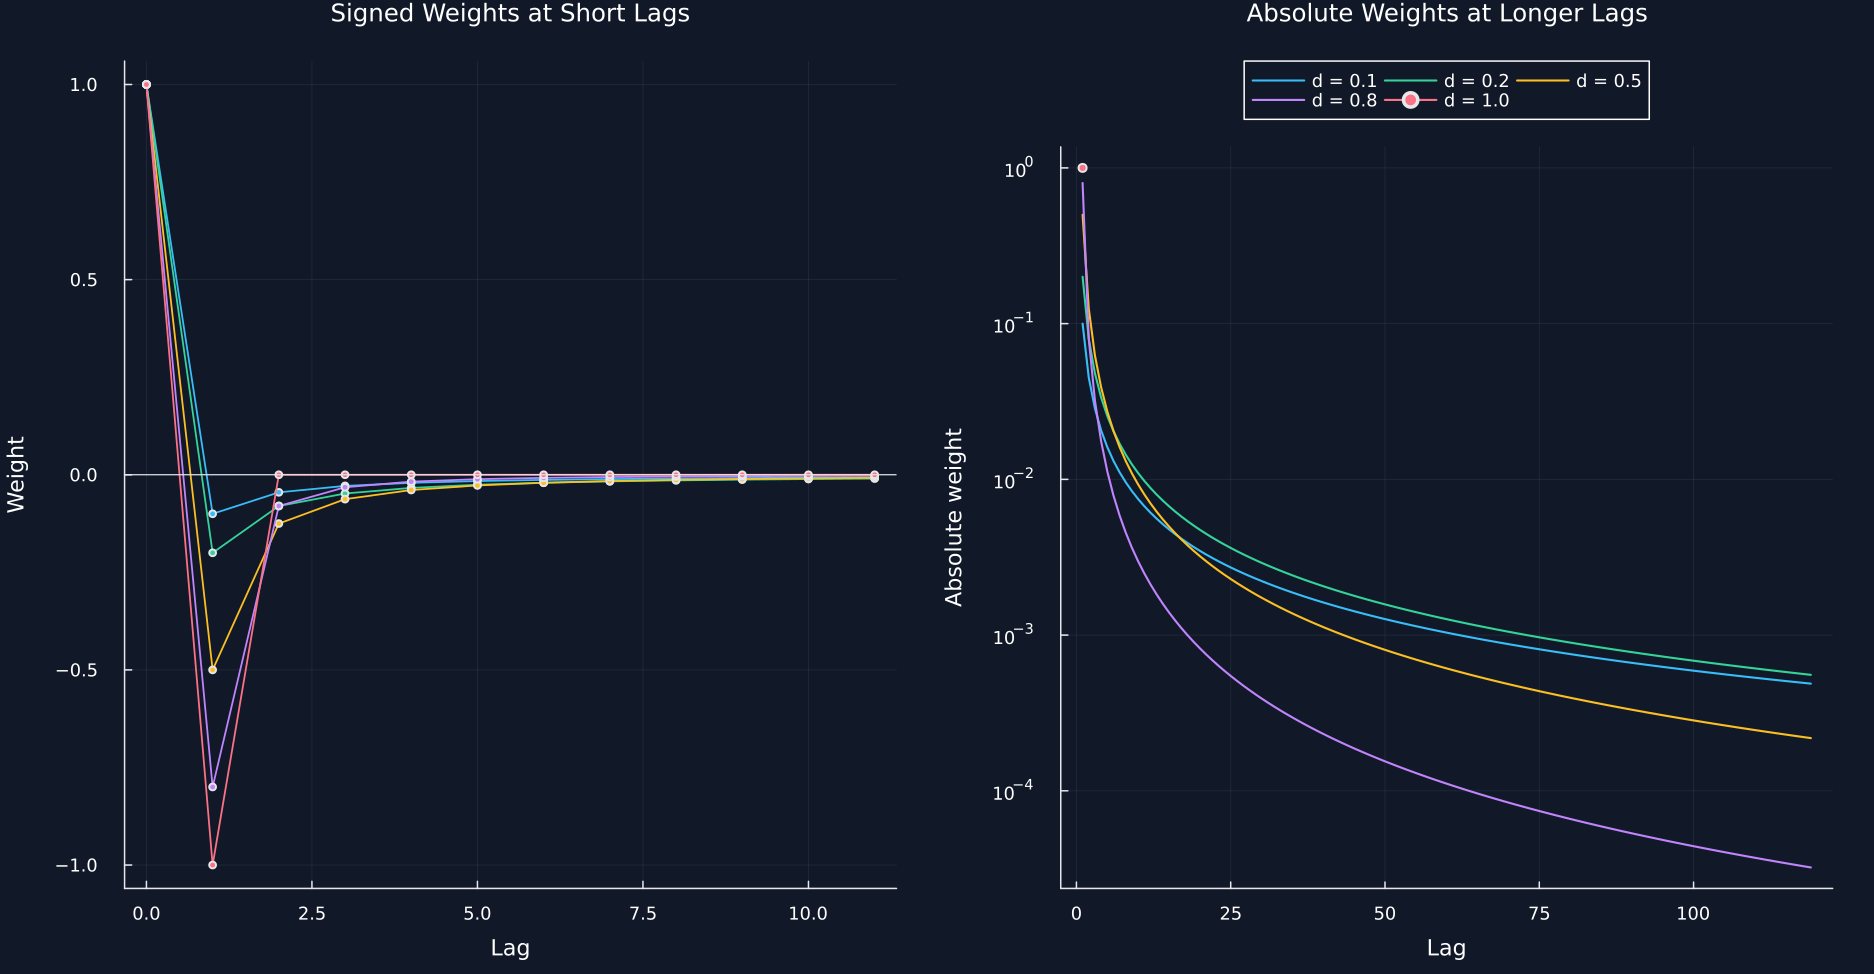

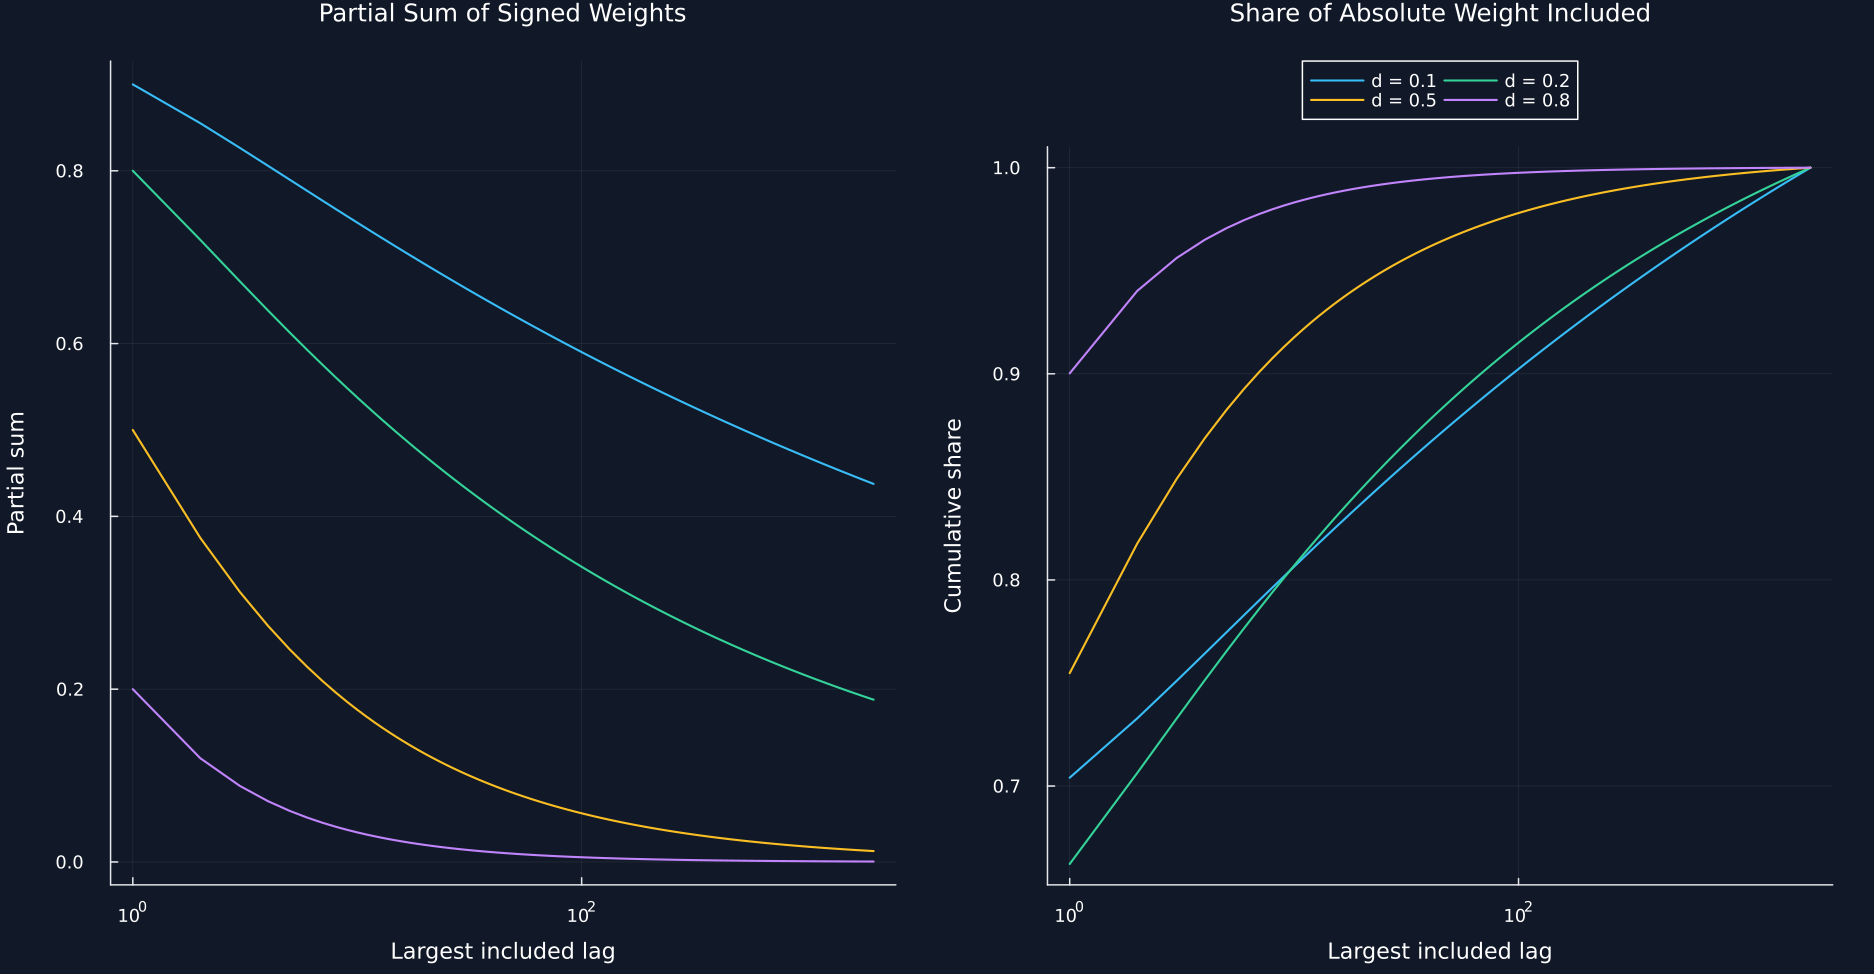

In [3]:
plot_degrees = [.1,.2,.5,.8,1.]
colors = [palette.cyan,palette.green,palette.amber,violet,palette.rose]
p1 = plot(;title="Signed Weights at Short Lags",xlabel="Lag",ylabel="Weight",legend=false)
p2 = plot(;title="Absolute Weights at Longer Lags",xlabel="Lag",ylabel="Absolute weight",yscale=:log10,legend=:outertop,legend_column=3)
for (degree,color) in zip(plot_degrees,colors)
    weights = natural_weights(degree,120)
    plot!(p1,0:11,weights[1:12];color,marker=:circle,markersize=2.5,linewidth=1.2,label="d = $degree")
    retained = findall(>(0),abs.(weights[2:end]))
    plot!(p2,retained,abs.(weights[retained.+1]);color,linewidth=1.4,label="d = $degree",marker=degree==1. ? :circle : :none,markersize=3.)
end
hline!(p1,[0.];color=palette.text,linewidth=.8,label=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1250,650)),paths,"binomial_weights")
p1 = plot(;title="Partial Sum of Signed Weights",xlabel="Largest included lag",ylabel="Partial sum",xscale=:log10,legend=false)
p2 = plot(;title="Share of Absolute Weight Included",xlabel="Largest included lag",ylabel="Cumulative share",xscale=:log10,legend=:outertop,legend_column=2)
for (degree,color) in zip(plot_degrees[1:4],colors[1:4])
    weights = natural_weights(degree,2000)
    plot!(p1,1:1999,cumsum(weights)[2:end];color,linewidth=1.4,label="d = $degree")
    plot!(p2,1:1999,(cumsum(abs.(weights))./sum(abs.(weights)))[2:end];color,linewidth=1.4,label="d = $degree")
end
save_figure(plot(p1,p2;layout=(1,2),size=(1250,650)),paths,"partial_weight_sums")


## Tracing fractional weights across long lags

For an order strictly between zero and one, every lagged weight is negative and its magnitude eventually declines toward zero:

$$
0<d<1\Longrightarrow -1<\omega_k<0\ (k\geq1),qquad
\left|\frac{\omega_k}{\omega_{k-1}}\right|=\frac{k-1-d}{k}<1\ (k\geq2),qquad
\lim_{k\to\infty}\omega_k=0.
$$

Here, $d\in(0,1)$ is the fractional order; $k\geq1$ is the lag; $\omega_k$ is the lag-$k$ weight. $|\cdot|$ is absolute value; the displayed ratio compares two consecutive weight magnitudes.

## Tests

In [4]:
w_zero = reverse(calculate_weights_std(0.,8))
w_one = reverse(calculate_weights_std(1.,8))
w_half = reverse(calculate_weights_std(.5,2000))
@assert length(minute_close)==44640
@assert length(close_prices)==2976
@assert issorted(close_index)
@assert all(isfinite,close_prices)
@assert w_zero==[1.,0.,0.,0.,0.,0.,0.,0.]
@assert w_one==[1.,-1.,0.,0.,0.,0.,0.,0.]
@assert calculate_weights_ffd(0.,1e-5)==[1.]
@assert calculate_weights_ffd(1.,1e-5)==[-1.,1.]
@assert maximum(recurrence_check[!,"Largest absolute difference"])<1e-15
@assert all(w_half[2:end].<0.)
@assert all(diff(abs.(w_half[2:end])).<0.)
@assert all(cumsum(w_half).>0.)
@assert last(cumsum(w_half))<.02
@assert isapprox(boundary_weights[(boundary_weights.Order.==.5).&(boundary_weights.Lag.==2),"Weight"][1],-.125)
@assert nrow(weight_decay_summary)==4
@assert isfile(joinpath(paths.figures,"binomial_weights.pdf"))
@assert isfile(joinpath(paths.figures,"partial_weight_sums.pdf"))
